# 01 · Data audit

Before estimating anything: does the data match its published description, and where are
the traps? This notebook writes `reports/metrics/01_audit.json`, two figures, and the
per-search flags (`data/interim/search_flags.parquet`) that define the analysis sample for
every later notebook.

Without the real data (CI, or anyone who has not downloaded it) the notebook runs on the
synthetic table from `hotelrank.synthetic` and writes nothing to `reports/`.

In [1]:
import sys
from pathlib import Path

def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from hotelrank import audit
from hotelrank.data import FIGURES_DIR, PRICE_CAP, PRICE_SORT_RHO, RESERVED_SLOTS, ROOT as PROJECT_ROOT, load
from hotelrank.records import write_metrics

COLUMNS = ["srch_id", "date_time", "site_id", "prop_id", "srch_destination_id", "position", "random_bool",
           "click_bool", "booking_bool", "price_usd", "srch_length_of_stay", "prop_starrating",
           "prop_review_score", "prop_location_score1", "prop_location_score2", "promotion_flag",
           "visitor_hist_starrating", "visitor_hist_adr_usd", "srch_query_affinity_score",
           "orig_destination_distance", "gross_bookings_usd"]
df, SOURCE = load(COLUMNS)
print(f"source: {SOURCE}, {len(df):,} impressions")

source: real, 9,917,530 impressions


## 1. Shape and the two arms

`random_bool = 1` marks searches whose results Expedia showed in random order.

In [2]:
searches = audit.per_search(df)
shape = {
    "impressions": int(len(df)),
    "searches": int(len(searches)),
    "hotels": int(df["prop_id"].nunique()),
    "destinations": int(df["srch_destination_id"].nunique()),
    "sites": int(df["site_id"].nunique()),
    "date_min": str(df["date_time"].min().date()),
    "date_max": str(df["date_time"].max().date()),
}
arms = audit.arm_summary(searches)
print(shape)
pd.DataFrame(arms)

{'impressions': 9917530, 'searches': 399344, 'hotels': 136886, 'destinations': 23715, 'sites': 34, 'date_min': '2012-11-01', 'date_max': '2013-06-30'}


,algorithm,random
searches,2.777980e+05,1.215460e+05
impressions,6.977878e+06,2.939652e+06
share_of_searches,6.956000e-01,3.044000e-01
searches_with_click,1.000000e+00,1.000000e+00
searches_with_booking,9.386000e-01,1.304000e-01
clicks_per_search,1.104100e+00,1.126800e+00
median_results,3.000000e+01,2.800000e+01


Every search has at least one click: the release contains only searches with a click, so
every result in this project describes engaged searches. Each search has at most one booking.

The share of searches ending in a booking differs enormously between the arms. That is
mostly how the release was sampled, not an effect of random ordering, so **booking rates are
never compared between arms**; every comparison is made within an arm.

In [3]:
selection = {
    "searches_with_click": round(float((searches["clicks"] > 0).mean()), 4),
    "max_bookings_per_search": int(searches["bookings"].max()),
    "bookings_without_click": int((df["booking_bool"] & ~df["click_bool"]).sum()),
}
print(selection)

{'searches_with_click': 1.0, 'max_bookings_per_search': 1, 'bookings_without_click': 0}


## 2. Positions: four slots are (almost) never filled

Slots 5, 11, 17 and 23 hold a few percent of the impressions of their neighbours in both
arms, and most searches skip exactly four slots. Those slots were presumably used for
something not released (an advert or a different unit). Positions are kept as logged; the
position-effect notebook works with displayed slots and reports the reserved ones separately.

reserved slots, impressions relative to neighbours: {'algorithm': {5: 0.0614, 11: 0.0835, 17: 0.0939, 23: 0.1001}, 'random': {5: 0.016, 11: 0.0184, 17: 0.0202, 23: 0.0208}}
skipped slots per search: {0: 4564, 1: 40458, 2: 35043, 3: 35287, 4: 278421, 5: 1887}


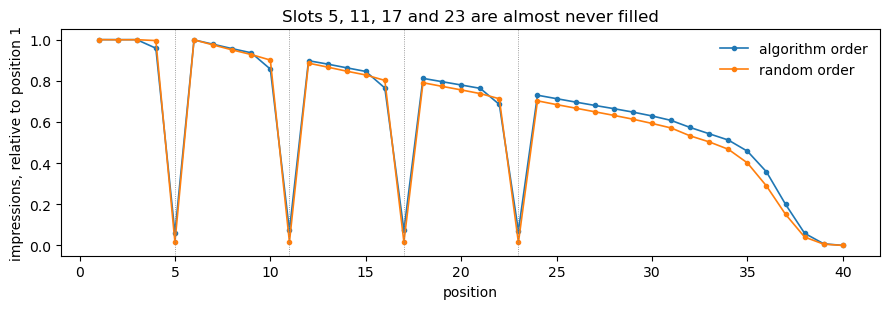

In [4]:
occ = audit.slot_occupancy(df)
reserved = audit.reserved_slot_share(occ)
gaps = audit.gaps_per_search(searches)
print("reserved slots, impressions relative to neighbours:", reserved)
print("skipped slots per search:", dict(list(gaps.items())[:6]))

fig, ax = plt.subplots(figsize=(9, 3.2))
for arm, colour in (("algorithm", "#1f77b4"), ("random", "#ff7f0e")):
    ax.plot(occ.index, occ[arm] / occ[arm].iloc[0], marker="o", ms=3, lw=1.2, label=f"{arm} order", color=colour)
for s in RESERVED_SLOTS:
    ax.axvline(s, color="grey", lw=0.6, ls=":")
ax.set(xlabel="position", ylabel="impressions, relative to position 1",
       title="Slots 5, 11, 17 and 23 are almost never filled")
ax.legend(frameon=False)
fig.tight_layout()

## 3. Prices

Prices are mostly per night (the median rises only modestly with length of stay), with a
long tail of errors. Rule: a search containing any price outside (0, $5,000] is dropped
from the analysis sample. Later notebooks use price relative to the other hotels in the
same search, which removes currency and per-night/per-stay differences.

In [5]:
prices = audit.price_summary(df)
print(prices)

{'quantiles': {'0.01': 34.0, '0.05': 51.0, '0.25': 85.0, '0.5': 122.07, '0.75': 185.0, '0.95': 356.0, '0.99': 599.0, '0.999': 2132.86}, 'max': 19726328.0, 'impressions_price_le_0': 54, 'share_above_cap': 0.000575, 'cap': 5000.0, 'share_above_10x_search_median': 0.000326, 'median_by_length_of_stay': {1: 112.0, 2: 125.0, 3: 132.8, 4: 141.0, 5: 145.0, 6: 148.0, 7: 144.6}}


## 4. Is the random arm actually random?

Under true random ordering, a hotel's position says nothing about its attributes. The check
demeans each attribute within its search (so differences between markets cancel) and
correlates it with position. The algorithm arm should show strong correlations; the random
arm should show none.

Two problems turn up in the real data:

1. **Some searches are sorted by price.** Their prices rise with position almost perfectly
   (about 5% of random-arm and 4% of algorithm-arm searches), most likely because the user
   chose "sort by price". They are flagged and dropped from both arms.
2. **A residual tilt remains in the random arm**: hotels with more stars sit slightly higher.
   It is diffuse rather than a few re-sorted searches (removing searches sorted by star rating
   barely changes it) and is about 40% of the algorithm arm's tilt, but it is not zero. The
   position-effect notebook therefore adjusts for hotel attributes and reports the estimate
   with and without that adjustment.

In [6]:
flags = audit.price_flags(df, searches)
BALANCE_COLS = ["prop_starrating", "prop_review_score", "prop_location_score1", "promotion_flag", "price_usd"]
keep_price_ok = ~flags["bad_price"]
keep_clean = keep_price_ok & ~flags["price_sorted"].fillna(False)

price_sorted_share = {
    name: round(float(flags.loc[(flags["random"] == flag) & flags["price_rho"].notna(), "price_sorted"].mean()), 4)
    for flag, name in audit.ARM_NAMES.items()
}
balance_all = audit.balance(df, BALANCE_COLS, keep=keep_price_ok)
balance_clean = audit.balance(df, BALANCE_COLS, keep=keep_clean)
# Sensitivity: also drop searches whose star ratings fall almost perfectly with position.
flags["star_rho"] = audit.within_search_rank_corr(df, "prop_starrating").reindex(flags.index)
star_sorted = flags["star_rho"] <= -0.9
balance_no_star_sorted = audit.balance(df, BALANCE_COLS, keep=keep_clean & ~star_sorted.fillna(False))
star_sorted_share = {name: round(float(star_sorted[(flags["random"] == flag) & flags["star_rho"].notna()].mean()), 4)
                     for flag, name in audit.ARM_NAMES.items()}
print("share of searches sorted by price:", price_sorted_share)
print("share sorted by stars (rho <= -0.9):", star_sorted_share,
      "random-arm star tilt without them:", balance_no_star_sorted["random"]["prop_starrating"])
pd.DataFrame({"algorithm": balance_all["algorithm"], "random (all)": balance_all["random"],
              "random (price-sorted removed)": balance_clean["random"]})

share of searches sorted by price: {'algorithm': 0.0364, 'random': 0.0549}
share sorted by stars (rho <= -0.9): {'algorithm': 0.0062, 'random': 0.0029} random-arm star tilt without them: -0.097


,algorithm,random (all),random (price-sorted removed)
prop_starrating,-0.2406,-0.0765,-0.0980
prop_review_score,-0.1463,-0.0240,-0.0366
prop_location_score1,-0.1103,-0.0113,-0.0158
promotion_flag,-0.2148,-0.0296,-0.0279
price_usd,-0.0033,-0.0004,-0.0199


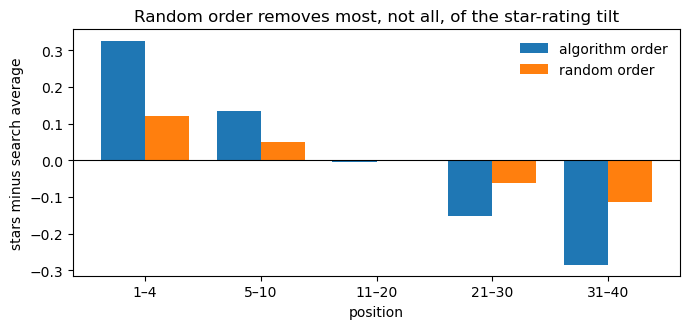

In [7]:
fig2, ax2 = plt.subplots(figsize=(7, 3.4))
series = {
    "algorithm order": audit.balance_by_bucket(df, "prop_starrating", False, keep=keep_clean),
    "random order": audit.balance_by_bucket(df, "prop_starrating", True, keep=keep_clean),
}
labels = [f"{int(i.left) + 1}–{int(i.right)}" for i in series["algorithm order"].index]
width = 0.38
for i, (name, s) in enumerate(series.items()):
    ax2.bar([j + (i - 0.5) * width for j in range(len(s))], s.values, width, label=name,
            color=["#1f77b4", "#ff7f0e"][i])
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xticks(range(len(labels)), labels)
ax2.set(xlabel="position", ylabel="stars minus search average",
        title="Random order removes most, not all, of the star-rating tilt")
ax2.legend(frameon=False)
fig2.tight_layout()

## 5. Analysis sample and missing data

In [8]:
sample = {
    "rule": f"drop searches with any price outside (0, {PRICE_CAP:,.0f}]; drop searches sorted by price "
            f"(within-search rank correlation of price with position >= {PRICE_SORT_RHO})",
    "searches_bad_price": int(flags["bad_price"].sum()),
    "searches_price_sorted": int((flags["price_sorted"].fillna(False) & ~flags["bad_price"]).sum()),
    "searches_kept": {name: int((keep_clean & (flags["random"] == flag)).sum())
                      for flag, name in audit.ARM_NAMES.items()},
    "impressions_kept": int(keep_clean.reindex(df["srch_id"]).sum()),
}
missing = audit.missing_share(df)
print(sample)
print(missing)

{'rule': 'drop searches with any price outside (0, 5,000]; drop searches sorted by price (within-search rank correlation of price with position >= 0.95)', 'searches_bad_price': 538, 'searches_price_sorted': 16773, 'searches_kept': {'algorithm': 267352, 'random': 114681}, 'impressions_kept': 9497418}
{'gross_bookings_usd': 0.9721, 'visitor_hist_starrating': 0.9491, 'visitor_hist_adr_usd': 0.9488, 'srch_query_affinity_score': 0.9359, 'orig_destination_distance': 0.3243, 'prop_location_score2': 0.2196, 'prop_review_score': 0.0015}


In [9]:
record = {
    "shape": shape, "arms": arms, "selection": selection,
    "reserved_slots_vs_neighbours": reserved, "skipped_slots_per_search": gaps,
    "prices": prices, "price_sorted_share": price_sorted_share,
    "balance_within_search_corr": {"price_ok": balance_all, "clean": balance_clean,
                                   "clean_without_star_sorted": balance_no_star_sorted},
    "star_sorted_share": star_sorted_share,
    "stars_minus_search_mean_by_position": {k: {str(i): round(float(v), 4) for i, v in s.items()}
                                            for k, s in series.items()},
    "analysis_sample": sample, "missing_share": missing,
}
path = write_metrics("01_audit", record, SOURCE)
print("wrote", path.relative_to(PROJECT_ROOT) if SOURCE == "real" else path.name)
if SOURCE == "real":
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / "01_reserved_slots.png", dpi=150)
    fig2.savefig(FIGURES_DIR / "01_random_arm_balance.png", dpi=150)
    flags.reset_index().rename(columns={"index": "srch_id"}).to_parquet(
        PROJECT_ROOT / "data" / "interim" / "search_flags.parquet", index=False)

wrote reports\metrics\01_audit.json
